In [2]:
!pip install -q ijson          
import os, gc, json, math, time, glob, random, zipfile, csv, warnings
warnings.filterwarnings("ignore")
 
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, PreTrainedTokenizerFast
 
try:
    import ijson
except ImportError:
    ijson = None
    print("ijson not installed -> falling back to json.load (needs lots of RAM for big files)")
 
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    HF_TOKEN = None

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 6.0 MB/s eta 0:00:00


In [16]:
QUICK_TEST = False
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
 
# ---- model (your values) ----
N_LAYER, N_HEAD, D_MODEL, BLOCK_SIZE, DROPOUT = 8, 8, 512, 1024, 0.1
 
# ---- training (your values) ----
MICRO_BATCH_SIZE, GRAD_ACCUM_STEPS = 4, 8
LEARNING_RATE, MIN_LR, WEIGHT_DECAY, WARMUP_RATIO = 3e-4, 3e-5, 0.1, 0.03
VAL_EVERY, EVAL_BATCHES, LOG_EVERY = 500, 50, 20
TIME_BUDGET_HOURS = 11.0          # stop + save before Kaggle's 12h limit
 
# ---- data mix: training-token budget per source (YOUR experiment knob) ----
TRAIN_BUDGETS = {
    "train_acts.json":           50_000_000,
    "train_high_courts.json":    50_000_000,
    "train_supreme_court.json":  50_000_000,
    "train_tribunals.json":      50_000_000,
}
KEEP_PROB = 0.3        # while streaming a file, keep each document with this probability
                       # (so we don't only take the first documents of the file)
VAL_FRAC = 0.05        # fraction of kept documents that go to validation
MAX_VAL_TOKENS = 5_000_000
 
# ---- generation (your sampling values) ----
TEMPERATURE, TOP_K, TOP_P = 0.8, 50, 0.95
TARGET_WORDS = 128     # competition needs exactly 128 WORDS
MAX_NEW_TOKENS = 384   # upper limit; generation stops early once 128 words exist
GEN_BATCH = 16
TEST_FILE_OVERRIDE = None   # set full path here if auto-detection picks the wrong file
 
OUTPUT_DIR = "/kaggle/working/phase1_model1"
 
if QUICK_TEST:
    TRAIN_BUDGETS = {k: 1_000_000 for k in TRAIN_BUDGETS}
    MAX_VAL_TOKENS, VAL_EVERY, EVAL_BATCHES, LOG_EVERY = 200_000, 50, 10, 10
    OUTPUT_DIR = "/kaggle/working/phase1_quick"
 
os.makedirs(OUTPUT_DIR, exist_ok=True)

Device: cuda Tesla T4


In [17]:
from huggingface_hub import snapshot_download

DATA_DIR = snapshot_download(
    "Exploration-Lab/CS-781-Capstone", repo_type="dataset", token=HF_TOKEN,
    allow_patterns=["*Phase_1*", "*Phase1*"],   # sirf Phase 1 ki files
    local_dir="/tmp/cs781_data",                # /tmp: /kaggle/working ki 20GB limit se bachne ke liye
)
all_json_files = (glob.glob("/kaggle/input/**/*.json", recursive=True)
                  + glob.glob(f"{DATA_DIR}/**/*.json", recursive=True))
print(len(all_json_files), "JSON files found")
def find_file(name):
    m = [f for f in all_json_files if os.path.basename(f).lower() == name.lower()]
    return m[0] if m else None
 
TRAIN_FILES = {name: find_file(name) for name in TRAIN_BUDGETS}
for name, path in TRAIN_FILES.items():
    print(f"{name:28s} -> {path}")
TRAIN_FILES = {k: v for k, v in TRAIN_FILES.items() if v is not None}
if not TRAIN_FILES:
    raise FileNotFoundError("No Phase-1 training files found. Attach the dataset to the notebook.")
 
def norm(s):
    return s.lower().replace(" ", "").replace("_", "").replace("-", "")
 
if TEST_FILE_OVERRIDE:
    TEST_FILE = TEST_FILE_OVERRIDE
else:
    cands = [f for f in all_json_files if "phase1test" in norm(os.path.basename(f))]
    if not cands:
        cands = [f for f in all_json_files if "test" in os.path.basename(f).lower()
                 and "phase" in norm(f) and "1" in os.path.basename(f)]
    TEST_FILE = cands[0] if cands else None
print("\nTEST FILE ->", TEST_FILE, "   <-- verify this is the Phase 1 test file!")

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

5 JSON files found
train_acts.json              -> /tmp/cs781_data/Phase_1_Pretraining/Train/train_acts.json
train_high_courts.json       -> /tmp/cs781_data/Phase_1_Pretraining/Train/train_high_courts.json
train_supreme_court.json     -> /tmp/cs781_data/Phase_1_Pretraining/Train/train_supreme_court.json
train_tribunals.json         -> /tmp/cs781_data/Phase_1_Pretraining/Train/train_tribunals.json

TEST FILE -> None    <-- verify this is the Phase 1 test file!


In [18]:
tokenizer = None
tok_jsons = glob.glob("/kaggle/input/**/tokenizer.json", recursive=True)
if tok_jsons:
    try:
        tokenizer = PreTrainedTokenizerFast(tokenizer_file=tok_jsons[0])
        print("Loaded tokenizer:", tok_jsons[0])
    except Exception as e:
        print("Could not load tokenizer.json:", e)
if tokenizer is None:
    tokenizer = AutoTokenizer.from_pretrained("gpt2", token=HF_TOKEN)
    print("Using GPT-2 BPE tokenizer")
 
if tokenizer.eos_token is None:
    tokenizer.add_special_tokens({"eos_token": "<|endoftext|>"})
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.model_max_length = int(1e9)   # we chunk ourselves
 
VOCAB_SIZE = len(tokenizer)
EOS_TOKEN_ID = tokenizer.eos_token_id
TOKEN_DTYPE = np.uint16 if VOCAB_SIZE < 65535 else np.uint32
print("Vocab size:", VOCAB_SIZE, "| EOS:", EOS_TOKEN_ID)

Using GPT-2 BPE tokenizer
Vocab size: 50257 | EOS: 50256


In [19]:
TRAIN_BIN = os.path.join(OUTPUT_DIR, "train.bin")
VAL_BIN = os.path.join(OUTPUT_DIR, "val.bin")
 
def iter_texts(path):
    """Yield one document text at a time. Handles [{"text":..}, ...] and {"1": {"text":..}, ...}."""
    def text_of(rec):
        if isinstance(rec, dict):
            for key in ("text", "content", "document", "body"):
                if isinstance(rec.get(key), str):
                    return rec[key]
        return rec if isinstance(rec, str) else None
 
    if ijson is not None:
        with open(path, "rb") as f:
            first = f.read(1)
            while first.isspace():
                first = f.read(1)
            f.seek(0)
            it = ijson.items(f, "item") if first == b"[" else (v for _, v in ijson.kvitems(f, ""))
            for rec in it:
                t = text_of(rec)
                if t: yield t
    else:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        for rec in (data if isinstance(data, list) else data.values()):
            t = text_of(rec)
            if t: yield t
        del data; gc.collect()
 
def build_token_files():
    if os.path.exists(TRAIN_BIN) and os.path.exists(VAL_BIN):
        print("Token files exist, skipping build."); return
    rng = random.Random(SEED)
    total_budget = sum(TRAIN_BUDGETS[k] for k in TRAIN_FILES)
    train_chunks, val_chunks = [], []
    for name, path in TRAIN_FILES.items():
        budget = TRAIN_BUDGETS[name]
        val_budget = int(MAX_VAL_TOKENS * budget / total_budget)
        n_tr = n_va = 0
        batch = []
 
        def flush(batch):
            nonlocal n_tr, n_va
            for ids in tokenizer(batch, add_special_tokens=False)["input_ids"]:
                arr = np.array(ids + [EOS_TOKEN_ID], dtype=TOKEN_DTYPE)   # EOS after EVERY document
                if rng.random() < VAL_FRAC:
                    if n_va < val_budget:
                        val_chunks.append(arr); n_va += len(arr)
                elif n_tr < budget:
                    train_chunks.append(arr); n_tr += len(arr)
 
        t0 = time.time()
        for text in iter_texts(path):
            if rng.random() > KEEP_PROB:
                continue
            batch.append(text)
            if len(batch) == 256:
                flush(batch); batch = []
                if n_tr >= budget and n_va >= val_budget:
                    break
        if batch:
            flush(batch)
        print(f"{name}: train {n_tr:,} | val {n_va:,} tokens | {time.time() - t0:.0f}s")
        if n_tr < budget:
            print(f"   (file ran out before budget - raise KEEP_PROB to get more from {name})")
    rng.shuffle(train_chunks)   # mix sources at document level
    np.concatenate(train_chunks).tofile(TRAIN_BIN)
    np.concatenate(val_chunks).tofile(VAL_BIN)
    del train_chunks, val_chunks; gc.collect()
 
build_token_files()
train_data = np.memmap(TRAIN_BIN, dtype=TOKEN_DTYPE, mode="r")
val_data = np.memmap(VAL_BIN, dtype=TOKEN_DTYPE, mode="r")
print(f"Train tokens: {len(train_data):,} | Val tokens: {len(val_data):,}")

train_acts.json: train 43,812,548 | val 1,292,838 tokens | 71s
   (file ran out before budget - raise KEEP_PROB to get more from train_acts.json)
train_high_courts.json: train 50,000,916 | val 1,250,395 tokens | 66s
train_supreme_court.json: train 50,004,702 | val 1,257,214 tokens | 76s
train_tribunals.json: train 50,008,112 | val 1,256,841 tokens | 70s
Train tokens: 193,826,278 | Val tokens: 5,057,288


In [20]:
B, T = MICRO_BATCH_SIZE, BLOCK_SIZE
 
def to_dev(x, y):
    if DEVICE.type == "cuda":
        return x.pin_memory().to(DEVICE, non_blocking=True), y.pin_memory().to(DEVICE, non_blocking=True)
    return x.to(DEVICE), y.to(DEVICE)
 
def make_xy(data, starts):
    x = torch.from_numpy(np.stack([data[i:i + T].astype(np.int64) for i in starts]))
    y = torch.from_numpy(np.stack([data[i + 1:i + 1 + T].astype(np.int64) for i in starts]))
    return to_dev(x, y)
 
def get_train_batch():
    return make_xy(train_data, np.random.randint(0, len(train_data) - T - 1, size=B))
 
VAL_STARTS = list(range(0, len(val_data) - T - 1, T))[: EVAL_BATCHES * B]
assert len(VAL_STARTS) > 0, "Validation set too small for one block - increase MAX_VAL_TOKENS"

In [21]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout):
        super().__init__()
        assert d_model % n_head == 0
        self.d_model = d_model
        self.n_head = n_head
        self.head_dim = d_model // n_head
        self.c_attn = nn.Linear(d_model, 3 * d_model)
        self.c_proj = nn.Linear(d_model, d_model)
        self.attn_dropout = dropout
        self.resid_dropout = nn.Dropout(dropout)
 
    def forward(self, x):
        B, T, C = x.shape
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.d_model, dim=2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        y = F.scaled_dot_product_attention(
            q, k, v, attn_mask=None,
            dropout_p=(self.attn_dropout if self.training else 0.0),
            is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.c_proj(y)
        y = self.resid_dropout(y)
        return y
 
 
class MLP(nn.Module):
    def __init__(self, d_model, dropout):
        super().__init__()
        self.fc = nn.Linear(d_model, 4 * d_model)
        self.proj = nn.Linear(4 * d_model, d_model)
        self.dropout = nn.Dropout(dropout)
 
    def forward(self, x):
        x = self.fc(x)
        x = F.gelu(x)
        x = self.proj(x)
        x = self.dropout(x)
        return x
 
 
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_head, dropout):
        super().__init__()
        self.ln_1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_head, dropout)
        self.ln_2 = nn.LayerNorm(d_model)
        self.mlp = MLP(d_model, dropout)
 
    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x
 
 
class LegalGPT(nn.Module):
    def __init__(self, vocab_size, block_size, n_layer, n_head, d_model, dropout):
        super().__init__()
        self.block_size = block_size
        self.wte = nn.Embedding(vocab_size, d_model)
        self.wpe = nn.Embedding(block_size, d_model)
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_head, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight
        self.apply(self._init_weights)
 
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
 
    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= self.block_size
        positions = torch.arange(0, T, device=idx.device)
        x = self.wte(idx) + self.wpe(positions)
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

In [22]:
MODEL_CFG = dict(vocab_size=VOCAB_SIZE, block_size=BLOCK_SIZE, n_layer=N_LAYER,
                 n_head=N_HEAD, d_model=D_MODEL, dropout=DROPOUT)
model = LegalGPT(**MODEL_CFG).to(DEVICE)
num_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {num_params:,} ({num_params / 1e6:.2f}M)")
if not (50_000_000 <= num_params <= 300_000_000):
    raise ValueError(f"{num_params / 1e6:.2f}M params - Phase 1 requires 50M-300M "
                     "(a smaller tokenizer vocab shrinks the embedding table)")

Parameters: 51,475,968 (51.48M)


In [23]:
decay, no_decay = [], []
for name, p in model.named_parameters():
    if p.requires_grad:
        (decay if p.dim() >= 2 and "wpe" not in name else no_decay).append(p)
optimizer = torch.optim.AdamW(
    [{"params": decay, "weight_decay": WEIGHT_DECAY}, {"params": no_decay, "weight_decay": 0.0}],
    lr=LEARNING_RATE, betas=(0.9, 0.95), eps=1e-8)
 
tokens_per_step = MICRO_BATCH_SIZE * BLOCK_SIZE * GRAD_ACCUM_STEPS
TOTAL_STEPS = max(1, len(train_data) // tokens_per_step)     # ~1 pass over the training tokens
WARMUP_STEPS = max(1, int(TOTAL_STEPS * WARMUP_RATIO))
print(f"Tokens/step {tokens_per_step:,} | total steps {TOTAL_STEPS:,} | warmup {WARMUP_STEPS}")
 
def get_lr(step):
    if step < WARMUP_STEPS:
        return LEARNING_RATE * (step + 1) / WARMUP_STEPS
    progress = min(max((step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS), 0.0), 1.0)
    return MIN_LR + (LEARNING_RATE - MIN_LR) * 0.5 * (1 + math.cos(math.pi * progress))
 
USE_AMP = DEVICE.type == "cuda"
USE_BF16 = USE_AMP and torch.cuda.get_device_capability()[0] >= 8   # T4 -> fp16
AMP_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and not USE_BF16)
 
def autocast():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=USE_AMP)
 
@torch.no_grad()
def estimate_loss():
    model.eval()
    losses = []
    for s in range(0, len(VAL_STARTS), B):
        x, y = make_xy(val_data, VAL_STARTS[s:s + B])
        with autocast():
            _, loss = model(x, y)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))

Tokens/step 32,768 | total steps 5,915 | warmup 177


In [24]:
LAST_CKPT = os.path.join(OUTPUT_DIR, "last.pt")    # model + optimizer (for resuming)
BEST_CKPT = os.path.join(OUTPUT_DIR, "best.pt")    # model only (best val loss)
LOG_CSV = os.path.join(OUTPUT_DIR, "log.csv")
 
global_step, best_val_loss = 0, float("inf")
if os.path.exists(LAST_CKPT):
    ck = torch.load(LAST_CKPT, map_location=DEVICE)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scaler.load_state_dict(ck["scaler"])
    global_step, best_val_loss = ck["step"], ck["best_val_loss"]
    print(f"Resumed from step {global_step} (best val {best_val_loss:.4f})")
 
def save_last():
    torch.save({"step": global_step, "best_val_loss": best_val_loss, "model": model.state_dict(),
                "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                "config": MODEL_CFG}, LAST_CKPT)
 
def save_best():
    torch.save({"step": global_step, "val_loss": best_val_loss, "model": model.state_dict(),
                "config": MODEL_CFG}, BEST_CKPT)
 
def log_row(row):
    new = not os.path.exists(LOG_CSV)
    with open(LOG_CSV, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["step", "split", "loss", "lr", "tok_per_s"])
        if new: w.writeheader()
        w.writerow(row)

In [29]:
print("\n================ TRAINING ================")
model.train()
start_time = t_log = time.time()
running = 0.0
while global_step < TOTAL_STEPS:
    current_lr = get_lr(global_step)
    for g in optimizer.param_groups:
        g["lr"] = current_lr
    optimizer.zero_grad(set_to_none=True)
    step_loss = 0.0
    for _ in range(GRAD_ACCUM_STEPS):
        x, y = get_train_batch()
        with autocast():
            _, loss = model(x, y)
            loss = loss / GRAD_ACCUM_STEPS
        scaler.scale(loss).backward()
        step_loss += loss.item()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer); scaler.update()
    global_step += 1
    running += step_loss
 
    if global_step % LOG_EVERY == 0:
        dt = time.time() - t_log; t_log = time.time()
        tps = LOG_EVERY * tokens_per_step / dt
        eta = (TOTAL_STEPS - global_step) * tokens_per_step / tps / 3600
        avg = running / LOG_EVERY; running = 0.0
        print(f"Step {global_step:5d}/{TOTAL_STEPS} | loss {avg:.4f} | lr {current_lr:.2e} "
              f"| {tps:,.0f} tok/s | ETA {eta:.2f}h")
        log_row({"step": global_step, "split": "train", "loss": avg, "lr": current_lr, "tok_per_s": tps})
 
    out_of_time = (time.time() - start_time) / 3600 > TIME_BUDGET_HOURS
    if global_step % VAL_EVERY == 0 or global_step == TOTAL_STEPS or out_of_time:
        val_loss = estimate_loss()
        print(f"  >> val loss {val_loss:.4f} | val ppl {math.exp(min(val_loss, 20)):.2f}")
        log_row({"step": global_step, "split": "val", "loss": val_loss, "lr": current_lr, "tok_per_s": ""})
        if val_loss < best_val_loss:
            best_val_loss = val_loss; save_best(); print("  >> best checkpoint saved")
        save_last()
    if out_of_time:
        print("Time budget reached. Checkpoint saved - re-run the notebook to resume."); break
 
print(f"Training time {(time.time() - start_time) / 3600:.2f}h | best val loss {best_val_loss:.4f} "
      f"(ppl {math.exp(min(best_val_loss, 20)):.2f})")


================ TRAINING ================
Step  4280/5915 | loss 0.7870 | lr 8.06e-05 | 90,122 tok/s | ETA 0.17h
Step  4300/5915 | loss 2.6002 | lr 7.95e-05 | 26,992 tok/s | ETA 0.54h
Step  4320/5915 | loss 2.6294 | lr 7.83e-05 | 26,970 tok/s | ETA 0.54h
Step  4340/5915 | loss 2.5743 | lr 7.72e-05 | 26,947 tok/s | ETA 0.53h
Step  4360/5915 | loss 2.5805 | lr 7.61e-05 | 26,959 tok/s | ETA 0.53h
Step  4380/5915 | loss 2.6660 | lr 7.50e-05 | 26,940 tok/s | ETA 0.52h
Step  4400/5915 | loss 2.6096 | lr 7.39e-05 | 26,973 tok/s | ETA 0.51h
Step  4420/5915 | loss 2.6200 | lr 7.28e-05 | 26,985 tok/s | ETA 0.50h
Step  4440/5915 | loss 2.6475 | lr 7.17e-05 | 27,002 tok/s | ETA 0.50h
Step  4460/5915 | loss 2.5798 | lr 7.07e-05 | 27,027 tok/s | ETA 0.49h
Step  4480/5915 | loss 2.5682 | lr 6.96e-05 | 27,017 tok/s | ETA 0.48h
Step  4500/5915 | loss 2.6138 | lr 6.86e-05 | 27,029 tok/s | ETA 0.48h
  >> val loss 2.7255 | val ppl 15.26
  >> best checkpoint saved
Step  4520/5915 | loss 2.5631 | lr 6.75e

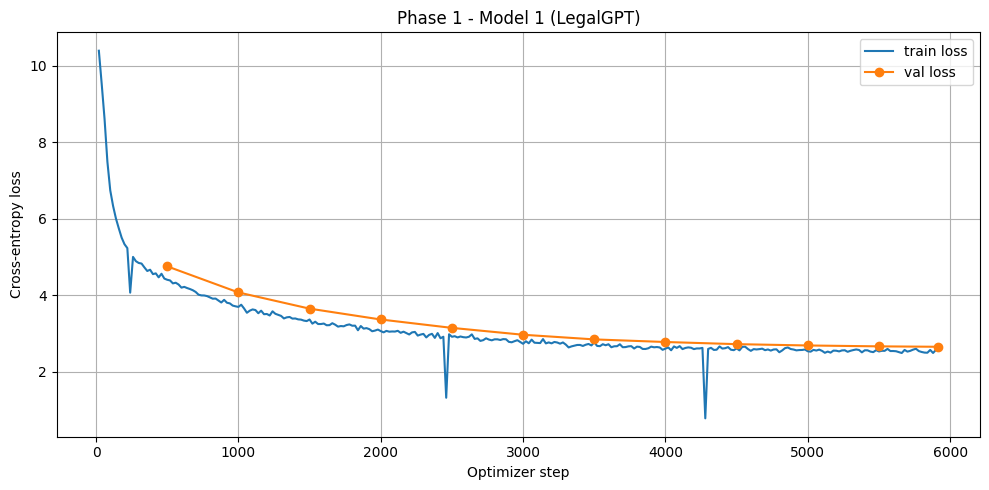

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(LOG_CSV)
plt.figure(figsize=(10, 5))
for split, style in [("train", "-"), ("val", "o-")]:
    d = df[df.split == split]
    plt.plot(d.step, d.loss, style, label=f"{split} loss")
plt.xlabel("Optimizer step"); plt.ylabel("Cross-entropy loss"); plt.title("Phase 1 - Model 1 (LegalGPT)")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve.png"), dpi=200); plt.show()

In [31]:
ck = torch.load(BEST_CKPT, map_location=DEVICE)
model.load_state_dict(ck["model"]); model.eval()
print(f"Loaded best checkpoint: step {ck['step']}, val loss {ck['val_loss']:.4f}")

Loaded best checkpoint: step 5915, val loss 2.6569


In [32]:
def sample_next(logits):
    logits = logits.float()
    logits[:, EOS_TOKEN_ID] = float("-inf")   # don't end the document; we need 128 words
    if TEMPERATURE <= 0:
        return logits.argmax(-1, keepdim=True)
    logits = logits / TEMPERATURE
    if TOP_K:
        kth = torch.topk(logits, min(TOP_K, logits.size(-1)), dim=-1).values[:, [-1]]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    if TOP_P < 1.0:
        sorted_logits, sorted_idx = torch.sort(logits, descending=True, dim=-1)
        probs = F.softmax(sorted_logits, dim=-1)
        remove = probs.cumsum(-1) - probs > TOP_P      # always keeps the top token
        sorted_logits = sorted_logits.masked_fill(remove, float("-inf"))
        logits = torch.full_like(logits, float("-inf")).scatter(-1, sorted_idx, sorted_logits)
    return torch.multinomial(F.softmax(logits, dim=-1), 1)
 
@torch.no_grad()
def generate_batch(prompt_ids_list):
    # Same-length prompts -> no padding needed. Each prompt keeps its LAST L tokens
    # (L = shortest prompt in the batch, capped at BLOCK_SIZE). Batches are length-sorted.
    L = min(min(len(p) for p in prompt_ids_list), BLOCK_SIZE)
    idx = torch.tensor([p[-L:] for p in prompt_ids_list], dtype=torch.long, device=DEVICE)
    start = idx.shape[1]
    for t in range(MAX_NEW_TOKENS):
        with autocast():
            logits, _ = model(idx[:, -BLOCK_SIZE:])   # sliding window over the last BLOCK_SIZE tokens
        idx = torch.cat([idx, sample_next(logits[:, -1, :])], dim=1)
        if (t + 1) % 32 == 0:
            texts = tokenizer.batch_decode(idx[:, start:], skip_special_tokens=True)
            if all(len(s.split()) >= TARGET_WORDS for s in texts):
                break
    texts = tokenizer.batch_decode(idx[:, start:], skip_special_tokens=True)
    return [" ".join(s.split()[:TARGET_WORDS]) for s in texts]
 
# quick look at one sample from the held-out validation data
sample_ids = val_data[:600].astype(np.int64).tolist()
torch.manual_seed(SEED)
print("PROMPT (end):", tokenizer.decode(sample_ids[-80:]))
print("\nGENERATED:", generate_batch([sample_ids])[0])

PROMPT (end):  Medicine Act, 1953;
(b) "Board" means the Bihar State Board of Homeopathic Medicine constituted under sub-section (1) of Section 3 of the Act;
(c) "President" means the President of the Bihar State Board of Homeopathic Medicine appointed under clause (a) of sub-section (1) of Section 3 of the Act, and for the purpose of

GENERATED: giving the Chairman or the Board of Directors of a University constituted under Section 4 of the Act, on the appointed day under Section 4 of the Act, for the conduct of the business of the Council, and includes the President of the State Board of Health Services and Vice-President of the District Council; (d) "person" means the Chancellor of the State Board of Health Services constituted under Section 6 of the Act, and the provisions of the Act. 3. In these rules, unless there is anything repugnant in the subject or context, "in accordance with the provisions of the Act" means the Rules made thereunder; (e) "Board of School" means the Board o

In [35]:
from huggingface_hub import list_repo_files
repo_files = list_repo_files("Exploration-Lab/CS-781-Capstone", repo_type="dataset", token=HF_TOKEN)
print([f for f in repo_files if "test" in f.lower()])
print([f for f in glob.glob("/tmp/cs781_data/**/*.json", recursive=True) if "train_" not in f])

['Phase_1_Pretraining/Test/test.json', 'Phase_2_LNER/Test/fold3-text.json', 'Phase_3_RR/Test/CL_test.json', 'Phase_3_RR/Test/IT_test.json', 'Phase_4_CJPE/Test/test.json', 'Phase_5_LSI/Test/test.json', 'Phase_6_Summ/Test/test.json', 'Phase_7_PCR/Test/test.json', 'Phase_7_PCR/Test/test_candidates.json']
['/tmp/cs781_data/Phase_1_Pretraining/Test/test.json']


In [37]:
TEST_FILE = "/tmp/cs781_data/Phase_1_Pretraining/Test/test.json"
print(TEST_FILE)

/tmp/cs781_data/Phase_1_Pretraining/Test/test.json


In [38]:
assert TEST_FILE is not None, "Set TEST_FILE_OVERRIDE to the Phase 1 test JSON path"
with open(TEST_FILE, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print("Test prompts:", len(test_data))
 
items = [(str(k), tokenizer.encode(v["text"] if isinstance(v, dict) else v, add_special_tokens=False))
         for k, v in test_data.items()]
items.sort(key=lambda it: len(it[1]))      # similar lengths together -> minimal truncation
torch.manual_seed(SEED)
predictions, t0 = {}, time.time()
for s in range(0, len(items), GEN_BATCH):
    batch = items[s:s + GEN_BATCH]
    for (key, _), text in zip(batch, generate_batch([ids for _, ids in batch])):
        predictions[key] = {"text": text}
    print(f"{min(s + GEN_BATCH, len(items))}/{len(items)} | {time.time() - t0:.0f}s")

Test prompts: 1000
16/1000 | 52s
32/1000 | 100s
48/1000 | 148s
64/1000 | 197s
80/1000 | 218s
96/1000 | 267s
112/1000 | 288s
128/1000 | 309s
144/1000 | 359s
160/1000 | 393s
176/1000 | 443s
192/1000 | 465s
208/1000 | 495s
224/1000 | 521s
240/1000 | 571s
256/1000 | 622s
272/1000 | 652s
288/1000 | 675s
304/1000 | 706s
320/1000 | 741s
336/1000 | 768s
352/1000 | 790s
368/1000 | 821s
384/1000 | 848s
400/1000 | 875s
416/1000 | 901s
432/1000 | 928s
448/1000 | 964s
464/1000 | 987s
480/1000 | 1038s
496/1000 | 1085s
512/1000 | 1112s
528/1000 | 1139s
544/1000 | 1175s
560/1000 | 1198s
576/1000 | 1250s
592/1000 | 1287s
608/1000 | 1328s
624/1000 | 1380s
640/1000 | 1433s
656/1000 | 1485s
672/1000 | 1517s
688/1000 | 1570s
704/1000 | 1598s
720/1000 | 1650s
736/1000 | 1703s
752/1000 | 1736s
768/1000 | 1774s
784/1000 | 1811s
800/1000 | 1840s
816/1000 | 1893s
832/1000 | 1947s
848/1000 | 1976s
864/1000 | 2014s
880/1000 | 2063s
896/1000 | 2102s
912/1000 | 2127s
928/1000 | 2182s
944/1000 | 2217s
960/1000 | 225

In [41]:
MAX_NEW_TOKENS = 1024          
for key in short:
    ids = tokenizer.encode(test_data[key]["text"], add_special_tokens=False)
    predictions[key] = {"text": generate_batch([ids])[0]}
    print(key, "->", len(predictions[key]["text"].split()), "words")

print("\nSample short output:\n", predictions[list(short)[0]]["text"][:500])

35 -> 128 words
811 -> 128 words
53 -> 128 words
830 -> 128 words
560 -> 128 words
650 -> 128 words
976 -> 128 words
638 -> 128 words
287 -> 128 words
399 -> 128 words
691 -> 128 words
82 -> 128 words
648 -> 128 words
598 -> 128 words
152 -> 128 words
838 -> 128 words
789 -> 128 words
220 -> 128 words
294 -> 128 words
8 -> 128 words
780 -> 128 words
658 -> 128 words

Sample short output:
 date of the first financial year. No further reference is made to the first part of the Note to Clause 2.03 (supra). It is also an obvious fact that the rates of monthly wages of the textile labourers would be treated as part of the table of the agreement which may have come into effect, as on the date of the notification. But, the second part of the Note, namely, the nature of which has been conferred on the part of the Note that a rate of twelve per cent of the rates payable on the part of the


In [42]:
assert set(predictions) == {str(k) for k in test_data}, "IDs don't match the test file"
short = {k: len(v["text"].split()) for k, v in predictions.items() if len(v["text"].split()) < TARGET_WORDS}
print(f"{len(predictions)} predictions | shorter than {TARGET_WORDS} words: {len(short)}")
if short:
    print("Examples:", list(short.items())[:5], "-> raise MAX_NEW_TOKENS")
 
prediction_path = os.path.join(OUTPUT_DIR, "prediction.json")
with open(prediction_path, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
zip_path = os.path.join(OUTPUT_DIR, "submission.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(prediction_path, arcname="prediction.json")    # must be at the zip ROOT
print("Submission ready:", zip_path)

1000 predictions | shorter than 128 words: 0
Submission ready: /kaggle/working/phase1_model1/submission.zip


In [43]:
with open(os.path.join(OUTPUT_DIR, "config.json"), "w") as f:
    json.dump({
        "model": {"architecture": "decoder-only Transformer (GPT-style, learned pos. emb.)",
                  **MODEL_CFG, "parameters": num_params},
        "data": {"budgets": TRAIN_BUDGETS, "keep_prob": KEEP_PROB, "train_tokens": int(len(train_data)),
                 "val_tokens": int(len(val_data))},
        "training": {"micro_batch": MICRO_BATCH_SIZE, "grad_accum": GRAD_ACCUM_STEPS,
                     "lr": LEARNING_RATE, "min_lr": MIN_LR, "weight_decay": WEIGHT_DECAY,
                     "warmup_ratio": WARMUP_RATIO, "steps": global_step, "best_val_loss": best_val_loss},
        "generation": {"temperature": TEMPERATURE, "top_k": TOP_K, "top_p": TOP_P,
                       "target_words": TARGET_WORDS, "max_new_tokens": MAX_NEW_TOKENS},
    }, f, indent=2)
print("Done.")

Done.
